In [1]:
import sys
sys.path.append("..")
from src.data import load_dataset, split_data

for name in ["telco", "bank"]:
    df = load_dataset(name)
    X_train, X_test, y_train, y_test = split_data(df)
    print(name, "train:", X_train.shape, "test:", X_test.shape)
    print("  churn rate train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))

telco train: (5634, 19) test: (1409, 19)
  churn rate train: 0.265  test: 0.265
bank train: (8000, 10) test: (2000, 10)
  churn rate train: 0.204  test: 0.204


In [2]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from src.models import make_logreg

scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name in ["telco", "bank"]:
    df = load_dataset(name)
    X_train, X_test, y_train, y_test = split_data(df)
    res = cross_validate(make_logreg(X_train), X_train, y_train, cv=cv, scoring=scoring)
    print(name, {k[5:]: round(v.mean(), 3) for k, v in res.items() if k.startswith("test_")})
    print(name, "accuracy of always guessing 'stays':", round(1 - y_train.mean(), 3))

telco {'accuracy': np.float64(0.802), 'precision': np.float64(0.653), 'recall': np.float64(0.544), 'f1': np.float64(0.593), 'roc_auc': np.float64(0.846), 'pr_auc': np.float64(0.661)}
telco accuracy of always guessing 'stays': 0.735
bank {'accuracy': np.float64(0.81), 'precision': np.float64(0.597), 'recall': np.float64(0.214), 'f1': np.float64(0.315), 'roc_auc': np.float64(0.763), 'pr_auc': np.float64(0.469)}
bank accuracy of always guessing 'stays': 0.796


In [3]:
import pandas as pd
from src.data import load_dataset, split_data
from src.models import make_logreg, make_rf, make_xgb
from src.evaluate import cv_report

results = []
for name in ["telco", "bank"]:
    X_train, X_test, y_train, y_test = split_data(load_dataset(name))
    for model_name, maker in [("LogReg", make_logreg), ("RandomForest", make_rf), ("XGBoost", make_xgb)]:
        scores = cv_report(maker(X_train), X_train, y_train)
        results.append({"dataset": name, "model": model_name, **scores})

pd.DataFrame(results)
pd.DataFrame(results).to_csv("../results/model_comparison_baseline.csv", index=False)

In [4]:
from src.models import make_balanced

rows = []
for name in ["telco", "bank"]:
    X_train, X_test, y_train, y_test = split_data(load_dataset(name))
    for kind in ["logreg", "xgb"]:
        for strategy in ["none", "class_weight", "smote", "undersample"]:
            model = make_balanced(kind, X_train, y_train, strategy)
            rows.append({"dataset": name, "model": kind, "strategy": strategy,
                         **cv_report(model, X_train, y_train)})

imb = pd.DataFrame(rows)
imb.to_csv("../results/imbalance_comparison.csv", index=False)
imb

,dataset,model,strategy,precision,recall,f1,roc_auc,pr_auc
0,telco,logreg,none,0.653,0.544,0.593,0.846,0.661
1,telco,logreg,class_weight,0.517,0.803,0.629,0.846,0.660
2,telco,logreg,smote,0.524,0.788,0.629,0.845,0.658
3,telco,logreg,undersample,0.514,0.801,0.626,0.846,0.661
4,telco,xgb,none,0.659,0.524,0.584,0.844,0.666
5,telco,xgb,class_weight,0.533,0.772,0.631,0.845,0.665
6,telco,xgb,smote,0.609,0.613,0.611,0.841,0.654
7,telco,xgb,undersample,0.509,0.791,0.619,0.840,0.646
8,bank,logreg,none,0.597,0.214,0.315,0.763,0.469
9,bank,logreg,class_weight,0.380,0.685,0.488,0.766,0.457


In [5]:
import pandas as pd
from src.data import load_dataset, split_data
from src.models import make_logreg, make_rf, make_xgb, make_lgbm, make_svm
from src.evaluate import cv_report

makers = [("LogReg", make_logreg), ("RandomForest", make_rf), ("XGBoost", make_xgb),
          ("LightGBM", make_lgbm), ("SVM", make_svm)]

results = []
for name in ["telco", "bank"]:
    X_train, X_test, y_train, y_test = split_data(load_dataset(name))
    for model_name, maker in makers:
        results.append({"dataset": name, "model": model_name,
                        **cv_report(maker(X_train), X_train, y_train)})

all_models = pd.DataFrame(results)
all_models.to_csv("../results/model_comparison_all.csv", index=False)
all_models

,dataset,model,precision,recall,f1,roc_auc,pr_auc
0,telco,LogReg,0.653,0.544,0.593,0.846,0.661
1,telco,RandomForest,0.668,0.496,0.569,0.845,0.659
2,telco,XGBoost,0.659,0.524,0.584,0.844,0.666
3,telco,LightGBM,0.657,0.522,0.581,0.840,0.656
4,telco,SVM,0.674,0.489,0.566,0.800,0.637
5,bank,LogReg,0.597,0.214,0.315,0.763,0.469
6,bank,RandomForest,0.785,0.446,0.569,0.859,0.684
7,bank,XGBoost,0.753,0.478,0.585,0.865,0.701
8,bank,LightGBM,0.746,0.501,0.600,0.865,0.702
9,bank,SVM,0.808,0.377,0.514,0.825,0.657


In [6]:
import pandas as pd
from src.data import load_dataset, split_data
from src.models import make_xgb
from src.evaluate import oof_proba, confusion_counts

oof = {}
for name in ["telco", "bank"]:
    X_train, X_test, y_train, y_test = split_data(load_dataset(name))
    oof[name] = oof_proba(make_xgb(X_train), X_train, y_train)
    pd.DataFrame({"proba": oof[name], "churn": y_train.values}).to_csv(
        f"../results/oof_xgb_{name}.csv", index=False)

    rows = [{"threshold": t, **confusion_counts(y_train, oof[name], t)}
            for t in [0.5, 0.4, 0.3, 0.2, 0.1]]
    print(name); print(pd.DataFrame(rows).to_string(index=False)); print()

telco
 threshold   TP   FP  FN   TN
       0.5  784  407 711 3732
       0.4  959  618 536 3521
       0.3 1126  957 369 3182
       0.2 1264 1358 231 2781
       0.1 1378 1961 117 2178

bank
 threshold   TP   FP  FN   TN
       0.5  779  254 851 6116
       0.4  915  423 715 5947
       0.3 1062  687 568 5683
       0.2 1234 1229 396 5141
       0.1 1434 2417 196 3953



telco | best threshold: 0.36 | cost per customer: 188.1
   at 0.5: 190.2 | flag nobody: 206.2 | flag everybody: 222.3
bank | best threshold: 0.32 | cost per customer: 185.7
   at 0.5: 187.4 | flag nobody: 203.8 | flag everybody: 242.6


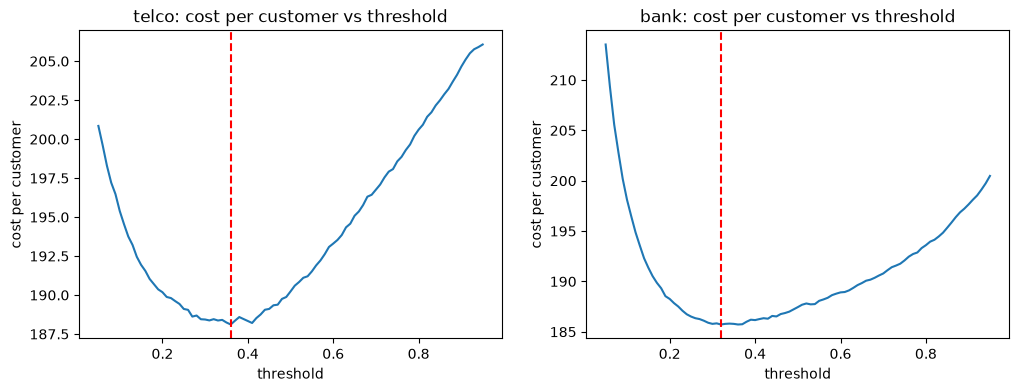

In [7]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.data import load_dataset, split_data
from src.evaluate import ASSUMPTIONS, cost_curve, total_cost, confusion_counts

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, ["telco", "bank"]):
    X_train, X_test, y_train, y_test = split_data(load_dataset(name))
    proba = pd.read_csv(f"../results/oof_xgb_{name}.csv")["proba"].values
    a = ASSUMPTIONS[name]
    n = len(y_train)

    curve = cost_curve(y_train, proba, **a)
    curve.to_csv(f"../results/cost_curve_{name}.csv", index=False)
    best = curve.loc[curve["total_cost"].idxmin()]

    per = lambda t: total_cost(confusion_counts(y_train, proba, t), **a) / n
    print(name, "| best threshold:", best["threshold"],
          "| cost per customer:", round(best["total_cost"] / n, 1))
    print("   at 0.5:", round(per(0.5), 1),
          "| flag nobody:", round(per(1.01), 1),
          "| flag everybody:", round(per(0.0), 1))

    ax.plot(curve["threshold"], curve["total_cost"] / n)
    ax.axvline(best["threshold"], color="red", linestyle="--")
    ax.set_title(f"{name}: cost per customer vs threshold")
    ax.set_xlabel("threshold"); ax.set_ylabel("cost per customer")
plt.savefig("../figures/cost_curves.png", bbox_inches="tight")
plt.show()

In [ ]:
from src.evaluate import sensitivity

for name in ["telco", "bank"]:
    X_train, X_test, y_train, y_test = split_data(load_dataset(name))
    proba = pd.read_csv(f"../results/oof_xgb_{name}.csv")["proba"].values
    sens = sensitivity(y_train, proba, ASSUMPTIONS[name]["V"])
    sens.to_csv(f"../results/sensitivity_{name}.csv", index=False)
    print(name, "- best threshold")
    print(sens.pivot_table(index="success_rate", columns="offer_pct_of_V", values="best_threshold"))
    print(name, "- saving vs flag nobody (%)")
    print(sens.pivot_table(index="success_rate", columns="offer_pct_of_V", values="saving_vs_nobody_%"))
    print()